# Online updating

Four of the six methods keep learning after calibration. This page is the loop
they learn in: predict, observe, `update`, repeat — plus what goes wrong when you
skip a step.

## Which methods are online

`IS_ONLINE` is a `ClassVar` — class metadata rather than a config field, so you
can ask before you build anything, and it never shows up in a constructor or in
`model_json_schema()`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoETS

from conformalforecast import (
    AdaptiveConformalInference,
    AggregatedAdaptiveConformalInference,
    ConformalizedQuantileRegression,
    NonexchangeableConformalPrediction,
    SequentialPredictiveConformalInference,
    SplitConformal,
)
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import method_state

METHODS = [
    SplitConformal,
    ConformalizedQuantileRegression,
    AdaptiveConformalInference,
    AggregatedAdaptiveConformalInference,
    NonexchangeableConformalPrediction,
    SequentialPredictiveConformalInference,
]
for cls in METHODS:
    print(f"{cls.__name__:42s} IS_ONLINE = {cls.IS_ONLINE}")

SplitConformal                             IS_ONLINE = False
ConformalizedQuantileRegression            IS_ONLINE = False
AdaptiveConformalInference                 IS_ONLINE = True
AggregatedAdaptiveConformalInference       IS_ONLINE = True
NonexchangeableConformalPrediction         IS_ONLINE = True
SequentialPredictiveConformalInference     IS_ONLINE = True


Offline methods still *have* an `update` method. It lives on the fitted object
that `calibrate` returns, and delegates to an `_update` hook, which the offline
fitted classes leave as the inherited no-op and the four online ones override. Calling it on an offline method is harmless, which means a
generic pipeline can call `update` unconditionally without branching on the
method type.

## The loop

`calibrate_cv` returns a fitted object, and that object is what learns: each
`update` mutates it in place and returns `None`.

In [ ]:
SEASON, ALPHA = 12, 0.1
TRAIN_END = 96  # stream the last 48 months

df = pd.read_csv("nbs/data/air_passengers.csv", parse_dates=["ds"])
panel = df["y"].to_numpy()[None, :]
train_df = df.iloc[:TRAIN_END].reset_index(drop=True)

sf = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="MS", n_jobs=1)
sf.fit(train_df)
forecaster = StatsForecastAdapter(
    sf=sf, train_df=train_df, horizon=1, freq="MS", model_name="AutoETS"
)

method = AdaptiveConformalInference(alpha=ALPHA, gamma=0.02)
fitted = method.calibrate_cv(forecaster, n_windows=48)

for t in range(TRAIN_END, panel.shape[1]):
    prediction = fitted.predict(panel[:, :t])  # 1. predict from what you know
    truth = panel[:, t : t + 1][:, None, :]  # 2. the observation arrives
    fitted.update(prediction.point, truth)  # 3. hand both back

print("state after the stream:")
for key, value in method_state(fitted).items():
    print(f"  {key:22s} {value if np.ndim(value) == 0 else np.round(value, 4)}")

state after the stream:
  alpha_t                [[0.052]]
  alpha_t_minus_alpha    [[-0.048]]
  n_observations         96
  gamma                  0.02


::: {.callout-important}
## `truth` must have the forecast's shape

`update` takes `(prediction, truth)` with **both** shaped
`(n_series, 1, horizon)` — the same 3-D `Forecast` shape `predict` returns, not
the flat `(n_series,)` slice you took out of your panel. The
`panel[:, t : t + 1][:, None, :]` above is that reshape: one series axis, one
sample, one horizon step.
:::

::: {.callout-note}
## Snapshots

Because `update` mutates the fitted object, keep a copy if you need the state
from before a stream — say, to replay a different stream from the same starting
point: `snapshot = fitted.model_copy(deep=True)`. The copy shares nothing with
the original, so later updates never reach it.
:::

## What updating buys

Run the same stream several ways: three online methods, one online method that is
calibrated but never fed, and split conformal for reference.

In [ ]:
def stream(cls, *, online=True, **kwargs):
    candidate = cls(alpha=ALPHA, **kwargs).calibrate_cv(forecaster, n_windows=48)
    lower, upper, covered = [], [], []
    for t in range(TRAIN_END, panel.shape[1]):
        prediction = candidate.predict(panel[:, :t])
        lo, hi = prediction.interval[0, 0, 0]
        lower.append(lo)
        upper.append(hi)
        covered.append(lo <= panel[0, t] <= hi)
        if online:
            candidate.update(prediction.point, panel[:, t : t + 1][:, None, :])
    return {"lower": np.array(lower), "upper": np.array(upper), "covered": np.array(covered)}


runs = {
    "ACI (updating)": stream(AdaptiveConformalInference, gamma=0.02),
    "ACI (never updated)": stream(AdaptiveConformalInference, online=False, gamma=0.02),
    "AgACI (updating)": stream(AggregatedAdaptiveConformalInference),
    "NexCP (updating)": stream(NonexchangeableConformalPrediction, rho=0.95),
    "split conformal": stream(SplitConformal, online=False),
}

print(f"{'method':24s}{'coverage':>10s}{'mean width':>13s}")
for name, run in runs.items():
    print(f"{name:24s}{run['covered'].mean():9.1%}{(run['upper'] - run['lower']).mean():13.1f}")

method                    coverage   mean width
ACI (updating)              93.8%         87.2
ACI (never updated)        100.0%        105.4
AgACI (updating)            91.7%         80.0
NexCP (updating)            93.8%         88.9
split conformal             85.4%         74.7


The second row is the one to look at, and it is not the failure mode most people
expect. A never-updated ACI does **not** degrade gracefully into split conformal.
It freezes at whatever `alpha_t` the calibration pass happened to leave behind —
0.016 here, not the 0.1 that was asked for — and then holds that forever. The
result is a 100% covering band, 40% wider than split conformal, aimed at a
confidence level nobody chose.

So an online method that is not fed is worse than an offline one: it is a fixed
interval at an arbitrary level, carrying the overhead of a controller that never
runs. If your pipeline cannot deliver truths back, pick an offline method
deliberately rather than inheriting one by accident.

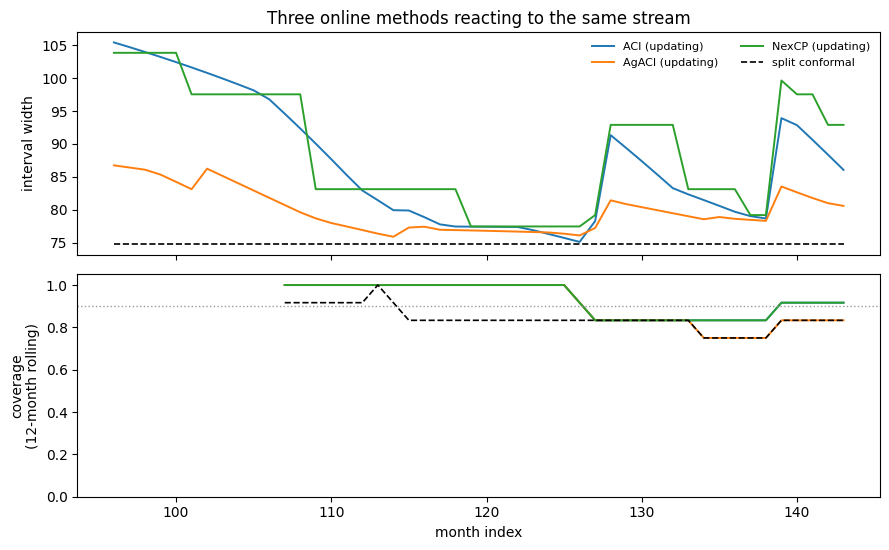

In [ ]:
months = np.arange(TRAIN_END, panel.shape[1])
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)

for i, name in enumerate(["ACI (updating)", "AgACI (updating)", "NexCP (updating)"]):
    top.plot(months, runs[name]["upper"] - runs[name]["lower"], color=f"C{i}", lw=1.4, label=name)
top.plot(
    months,
    runs["split conformal"]["upper"] - runs["split conformal"]["lower"],
    color="k",
    lw=1.2,
    ls="--",
    label="split conformal",
)
top.set_ylabel("interval width")
top.set_title("Three online methods reacting to the same stream")
top.legend(fontsize=8, frameon=False, ncol=2)

window = 12
for i, name in enumerate(
    ["ACI (updating)", "AgACI (updating)", "NexCP (updating)", "split conformal"]
):
    covered = runs[name]["covered"].astype(float)
    rolled = np.convolve(covered, np.ones(window) / window, mode="valid")
    style = (
        {"color": "k", "lw": 1.2, "ls": "--"}
        if name == "split conformal"
        else {"color": f"C{i}", "lw": 1.4}
    )
    bottom.plot(months[window - 1 :], rolled, label=name, **style)
bottom.axhline(1 - ALPHA, color="0.6", lw=1, ls=":")
bottom.set_ylabel(f"coverage\n({window}-month rolling)")
bottom.set_xlabel("month index")
bottom.set_ylim(0, 1.05)
fig.tight_layout()

## Online state survives calibration

`calibrate_cv` does not merely collect residuals for an online method — it rolls
the method's state forward through every calibration window. By the time the
stream starts, `alpha_t` has already moved.

In [ ]:
print(f"before calibration  alpha_t = {ALPHA:.4f} (the configured alpha)")
fresh = AdaptiveConformalInference(alpha=ALPHA, gamma=0.02).calibrate_cv(forecaster, n_windows=48)
print(f"after  calibration  alpha_t = {fresh.alpha_t_[0, 0]:.4f}")
print(f"observations seen   {method_state(fresh)['n_observations']}")

before calibration  alpha_t = 0.1000 (the configured alpha)
after  calibration  alpha_t = 0.0160
observations seen   48


This is why `n_observations` after the 48-month stream above reads 96 rather than
48, and why an online method's diagnostics are cumulative across both phases.

## Updating out of order

`update` assumes the truth you hand it is the one that followed the prediction
you hand it. Nothing checks that — the arrays have no timestamps — so an
out-of-order or duplicated update corrupts the state silently.

::: {.callout-warning}
## Three rules for a production loop

1. **Update once per observation.** Replaying the same truth twice tells the
   controller it missed (or hit) twice.
2. **Update in time order.** [NexCP](../methods/nexcp) weights by position and
   [SPCI](../methods/spci) regresses on a residual sequence; both read the order
   as time.
3. **Pair the truth with the prediction that preceded it**, not with the newest
   forecast. Passing `prediction.point` straight through, as above, makes this
   automatic.
:::

## Next

- [ACI](../methods/aci) — the controller, in detail.
- [AgACI](../methods/agaci) — several controllers, aggregated.
- [Diagnostics](diagnostics) — `rolling_coverage` and the per-method state
  helpers, including `method_state` used above.